<a href="https://colab.research.google.com/github/FarkhodStudy/AI_Electronic-and-Computer-Dept/blob/main/QWE1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Required libraries
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt

# 1. Create data
data = {
    'Income': [60000, 55000, 70000, 50000, 52000,
               48000, 45000, 40000, 30000, 35000,
               60000, 52000, 70000, 48000, 45000,
               50000, 51000, 49000, 53000, 55000],
    'Age':    [32, 35, 40, 30, 33,
               28, 25, 22, 27, 20,
               25, 28, 29, 30, 31,
               25, 29, 35, 31, 30],
    'Buy':    ['Yes', 'Yes', 'Yes', 'Yes', 'Yes',
               'No', 'No', 'No', 'No', 'No',
               'No', 'No', 'No', 'No', 'No',
               'No', 'No', 'No', 'Yes', 'Yes']
}

# Create DataFrame
df = pd.DataFrame(data)

# 2. Print DataFrame
print("--- DataFrame Output ---")
print(df)

--- DataFrame Output ---
    Income  Age  Buy
0    60000   32  Yes
1    55000   35  Yes
2    70000   40  Yes
3    50000   30  Yes
4    52000   33  Yes
5    48000   28   No
6    45000   25   No
7    40000   22   No
8    30000   27   No
9    35000   20   No
10   60000   25   No
11   52000   28   No
12   70000   29   No
13   48000   30   No
14   45000   31   No
15   50000   25   No
16   51000   29   No
17   49000   35   No
18   53000   31  Yes
19   55000   30  Yes


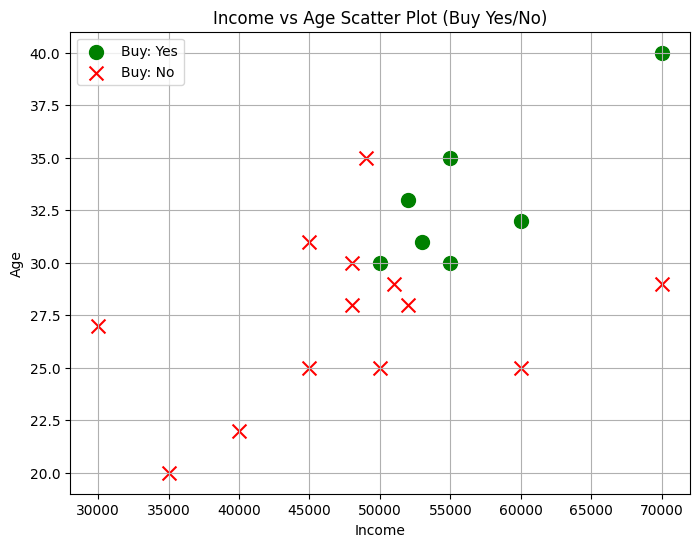

In [2]:
# Scatter plot
plt.figure(figsize=(8,6))

# Buy = Yes
yes = df[df['Buy'] == 'Yes']
plt.scatter(yes['Income'], yes['Age'], color='green', label='Buy: Yes', s=100, marker='o')

# Buy = No
no = df[df['Buy'] == 'No']
plt.scatter(no['Income'], no['Age'], color='red', label='Buy: No', s=100, marker='x')

# 그래프 설정
plt.xlabel('Income')
plt.ylabel('Age')
plt.title('Income vs Age Scatter Plot (Buy Yes/No)')
plt.legend()
plt.grid(True)
plt.show()

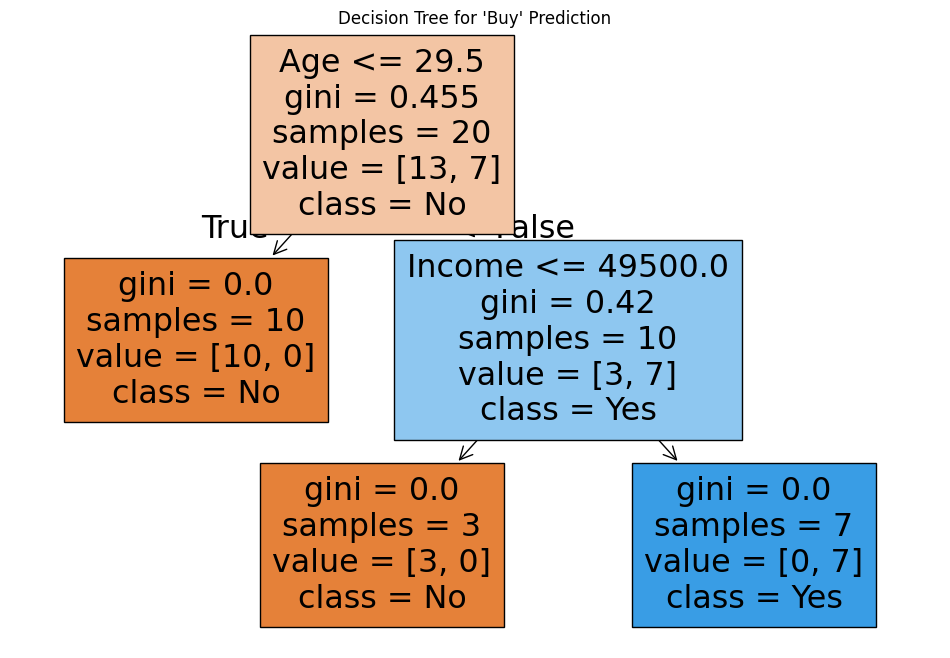

In [3]:
# 3. Define Features (X) and Target (y)
X = df[['Income', 'Age']]
y = df['Buy']

# 4. Train Decision Tree Model
model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)

# 5. Visualize the Decision Tree
plt.figure(figsize=(12, 8))
tree.plot_tree(model,
               feature_names=['Income', 'Age'],
               class_names=['No', 'Yes'],
               filled=True)
plt.title("Decision Tree for 'Buy' Prediction")
plt.show()

In [4]:
# 5️. Prediction
sample = pd.DataFrame({'Income':[ 47000, 51000], 'Age':[29, 31]})
pred = model.predict(sample)
print(pred)  # ['Yes', 'No']

####  Part 5 ###
# 6. Model rule print. not function f(x)
from sklearn.tree import export_text

# 트리의 규칙을 텍스트 형태로 출력
tree_rules = export_text(model, feature_names=['Income', 'Age'])
print(tree_rules)

['No' 'Yes']
|--- Age <= 29.50
|   |--- class: No
|--- Age >  29.50
|   |--- Income <= 49500.00
|   |   |--- class: No
|   |--- Income >  49500.00
|   |   |--- class: Yes



In [5]:
# Dicision boundary
import numpy as np
# 4️. Scatter plot과 결정 경계 시각화
plt.figure(figsize=(10,6))

# 결정 경계를 위한 meshgrid 생성
x_min, x_max = X['Income'].min() - 5000, X['Income'].max() + 5000
y_min, y_max = X['Age'].min() - 2, X['Age'].max() + 2
xx, yy = np.meshgrid(np.arange(x_min, x_max, 500),
                     np.arange(y_min, y_max, 0.5))
# 각 점에 대해 예측
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = np.array([1 if val=='Yes' else 0 for val in Z])
Z = Z.reshape(xx.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


<Figure size 1000x600 with 0 Axes>

New Data Prediction -> Income: 62000, Age: 32 ==> Buy: Yes


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


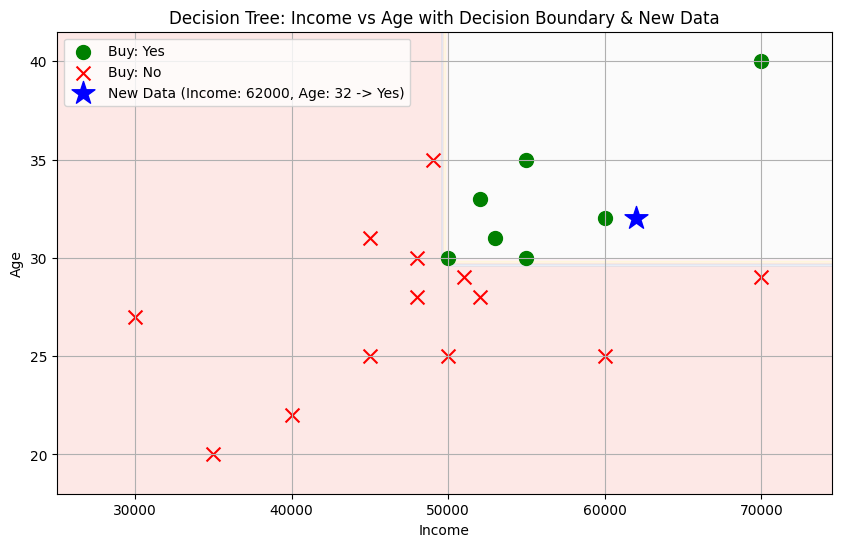

In [9]:
# ==========================================
# 새로운 데이터 예측 및 결정 경계 시각화 (단건 적용)
# ==========================================
import numpy as np

# 1. 새로운 데이터 정의 (오직 이 데이터만 적용)
new_income = 62000
new_age = 32

# 2. 모델 예측 수행
new_sample = pd.DataFrame({'Income': [new_income], 'Age': [new_age]})
new_pred = model.predict(new_sample)[0]
print(f"New Data Prediction -> Income: {new_income}, Age: {new_age} ==> Buy: {new_pred}")

# 3. 결정 경계를 위한 meshgrid 생성
x_min, x_max = X['Income'].min() - 5000, X['Income'].max() + 5000
y_min, y_max = X['Age'].min() - 2, X['Age'].max() + 2
xx, yy = np.meshgrid(np.arange(x_min, x_max, 500),
                     np.arange(y_min, y_max, 0.5))

# 각 격자점에 대한 예측값 계산
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = np.array([1 if val=='Yes' else 0 for val in Z])
Z = Z.reshape(xx.shape)

# 4. 시각화 플롯 생성
plt.figure(figsize=(10, 6))

# 결정 경계 배경 색상 채우기
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Pastel1)

# 기존 학습 데이터 산점도
yes = df[df['Buy'] == 'Yes']
no = df[df['Buy'] == 'No']
plt.scatter(yes['Income'], yes['Age'], color='green', label='Buy: Yes', s=100, marker='o')
plt.scatter(no['Income'], no['Age'], color='red', label='Buy: No', s=100, marker='x')

# 새로운 데이터(New Data)만 파란색 별표로 강조 표시
plt.scatter([new_income], [new_age], color='blue', marker='*', s=300,
            label=f'New Data (Income: {new_income}, Age: {new_age} -> {new_pred})')

# 그래프 레이블 및 설정
plt.xlabel('Income')
plt.ylabel('Age')
plt.title('Decision Tree: Income vs Age with Decision Boundary & New Data')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()